# How did Netflix's catalogue change as it went global?

**Research question.** Between 2016 and 2019, as Netflix expanded worldwide, did the titles it *added* shift towards (1) TV shows, (2) productions from outside the United States and (3) newer releases?

**Data.** [Netflix Movies and TV Shows](https://www.kaggle.com/datasets/shivamb/netflix-shows) by Shivam Bansal on Kaggle: 6,234 titles available on Netflix in January 2020, with the date each was added. The notebook reads `netflix_titles.csv` if it is next to it, and otherwise downloads a public copy of the same release. This analysis uses the January 2020 release of the dataset; later releases add titles from 2020–21.

**Important limitation.** The data is a *snapshot* of what was still on Netflix in January 2020. Titles added in earlier years and later removed are missing, and licensed content is removed more often than originals. Earlier years are therefore under-counted, which can exaggerate growth trends. Results describe the 2020 catalogue by year of addition, not everything Netflix ever added.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf

INK, SURF, IVORY, MUTED, PINK, AMBER, VIOLET, CYAN = '#0A0A13','#16151F','#F4F1EA','#9A93A8','#E8577C','#E8B86D','#6D5EF5','#38BDF8'
plt.rcParams.update({'figure.facecolor':INK,'axes.facecolor':INK,'axes.edgecolor':'#3a3747','axes.labelcolor':MUTED,
    'xtick.color':MUTED,'ytick.color':MUTED,'text.color':IVORY,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,
    'axes.grid':True,'axes.axisbelow':True,'grid.color':'#24222f','grid.linewidth':0.8,'savefig.facecolor':INK,'savefig.dpi':160})

try:
    df = pd.read_csv('netflix_titles.csv')
except FileNotFoundError:   # same January 2020 release, public copy
    df = pd.read_csv('https://raw.githubusercontent.com/allenkong221/netflix-titles-dataset/master/netflix_titles.csv')
df['date_added'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce')
df['year_added'] = df['date_added'].dt.year
print(df.shape); df.head(3)

(6234, 13)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China",2019-09-09,2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...,2019.0
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,2016-09-09,2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...,2016.0
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,2018-09-08,2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob...",2018.0


## 1. Cleaning and scope

In [2]:
print('Missing date_added:', df['date_added'].isna().sum())
print('Exact duplicate rows (title, type, release year):', df.duplicated(['title','type','release_year']).sum())
df = df.drop_duplicates(['title','type','release_year']).dropna(subset=['date_added'])
print(df['year_added'].value_counts().sort_index().to_string())
# Analysis window: full calendar years with enough additions to compare
win = df[df['year_added'].between(2016, 2019)].copy()
win['year_added'] = win['year_added'].astype(int)
print('Titles in window:', len(win))

Missing date_added: 11
Exact duplicate rows (title, type, release year): 3
year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       7
2013.0      12
2014.0      25
2015.0      90
2016.0     456
2017.0    1299
2018.0    1782
2019.0    2347
2020.0     184
Titles in window: 5884


## 2. Did additions shift towards TV shows?

In [3]:
tv = pd.crosstab(win['year_added'], win['type'])
tv['TV share'] = tv['TV Show'] / tv.sum(axis=1)
print(tv)
chi2, p, dof, _ = stats.chi2_contingency(tv[['Movie','TV Show']])
print(f'Chi-square test of type x year: chi2={chi2:.1f}, dof={dof}, p={p:.3g}')
m_tv = smf.logit('is_tv ~ year_added', data=win.assign(is_tv=(win['type']=='TV Show').astype(int))).fit(disp=0)
print(f"Odds of an addition being a TV show change by x{np.exp(m_tv.params['year_added']):.2f} per year (p={m_tv.pvalues['year_added']:.3g})")

type        Movie  TV Show  TV share
year_added                          
2016          264      192  0.421053
2017          912      387  0.297921
2018         1290      492  0.276094
2019         1545      802  0.341713
Chi-square test of type x year: chi2=45.2, dof=3, p=8.26e-10
Odds of an addition being a TV show change by x0.99 per year (p=0.721)


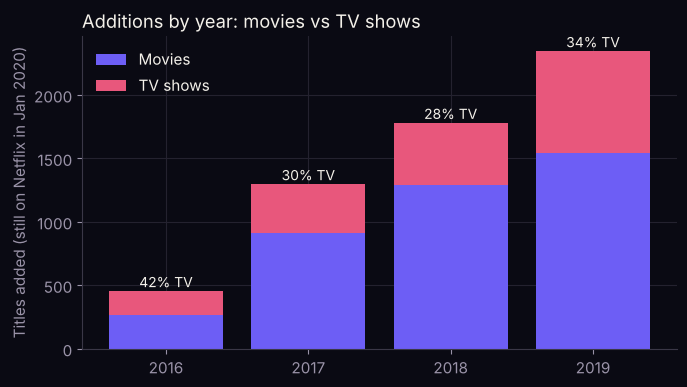

In [4]:
fig, ax = plt.subplots(figsize=(7,4))
years = tv.index.astype(str)
ax.bar(years, tv['Movie'], color=VIOLET, label='Movies')
ax.bar(years, tv['TV Show'], bottom=tv['Movie'], color=PINK, label='TV shows')
for i,(y,r) in enumerate(tv.iterrows()):
    ax.text(i, r['Movie']+r['TV Show']+30, f"{r['TV share']:.0%} TV", ha='center', color=IVORY, fontsize=10)
ax.set_ylabel('Titles added (still on Netflix in Jan 2020)'); ax.legend(frameon=False)
ax.set_title('Additions by year: movies vs TV shows', loc='left', color=IVORY)
fig.tight_layout(); fig.savefig('figures/01_type_by_year.png'); plt.show()

## 3. Did additions shift towards productions from outside the US?

In [5]:
c = win.dropna(subset=['country']).copy()
c['countries'] = c['country'].str.split(',').apply(lambda xs: [x.strip() for x in xs if x.strip()])
c['has_us'] = c['countries'].apply(lambda xs: 'United States' in xs)
c['international'] = ~c['has_us']
intl = c.groupby('year_added')['international'].agg(['mean','size']).rename(columns={'mean':'Non-US share','size':'Titles with country'})
print(intl)
m_int = smf.logit('international ~ year_added', data=c.assign(international=c['international'].astype(int))).fit(disp=0)
print(f"Odds of an addition having no US production country change by x{np.exp(m_int.params['year_added']):.2f} per year (p={m_int.pvalues['year_added']:.3g})")
print('Titles excluded for missing country:', win['country'].isna().sum())

            Non-US share  Titles with country
year_added                                   
2016            0.518182                  440
2017            0.602617                 1223
2018            0.609622                 1642
2019            0.520207                 2128
Odds of an addition having no US production country change by x0.92 per year (p=0.00474)
Titles excluded for missing country: 451


In [6]:
ex = c.explode('countries')
top = ex.groupby(['countries','year_added']).size().unstack(fill_value=0)
top = top.loc[top.sum(axis=1).sort_values(ascending=False).index[:10]]
top['2019 vs 2016'] = (top[2019] / top[2016].replace(0, np.nan)).round(1)
print(top)

year_added      2016  2017  2018  2019  2019 vs 2016
countries                                           
United States    212   486   641  1021           4.8
India             15   202   363   248          16.5
United Kingdom    54   140   158   209           3.9
Canada            35    72    85   100           2.9
France            31    58    69    95           3.1
Japan             33    46    56    84           2.5
Spain             18    44    46    66           3.7
South Korea       10    46    35    67           6.7
Germany           14    33    36    51           3.6
Mexico             9    36    34    42           4.7


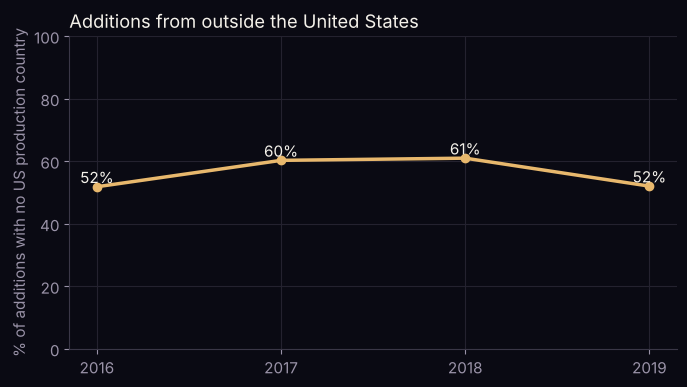

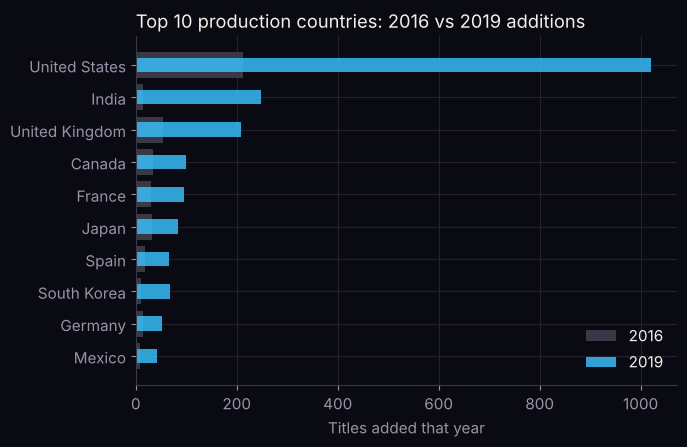

In [7]:
fig, ax = plt.subplots(figsize=(7,4))
ax.plot(intl.index.astype(str), intl['Non-US share']*100, marker='o', color=AMBER, lw=2.5)
for x,yv in zip(intl.index.astype(str), intl['Non-US share']*100): ax.text(x, yv+1.2, f'{yv:.0f}%', ha='center', color=IVORY)
ax.set_ylim(0, 100); ax.set_ylabel('% of additions with no US production country')
ax.set_title('Additions from outside the United States', loc='left', color=IVORY)
fig.tight_layout(); fig.savefig('figures/02_international_share.png'); plt.show()

t10 = top.drop(columns='2019 vs 2016').iloc[::-1]
fig, ax = plt.subplots(figsize=(7,4.6))
ax.barh(t10.index, t10[2016], color='#3a3747', label='2016')
ax.barh(t10.index, t10[2019], color=CYAN, alpha=0.85, height=0.45, label='2019')
ax.set_xlabel('Titles added that year'); ax.legend(frameon=False, loc='lower right')
ax.set_title('Top 10 production countries: 2016 vs 2019 additions', loc='left', color=IVORY)
fig.tight_layout(); fig.savefig('figures/03_top_countries.png'); plt.show()

## 4. Were additions getting newer?

In [8]:
win['age_at_add'] = win['year_added'] - win['release_year']
win = win[win['age_at_add'] >= 0]   # drop impossible negatives (release year after year added)
age = win.groupby('year_added')['age_at_add'].agg(median='median', fresh=lambda s: (s<=1).mean(), n='size')
print(age)
h, p_kw = stats.kruskal(*[g['age_at_add'] for _, g in win.groupby('year_added')])
print(f'Kruskal-Wallis on age at addition across years: H={h:.1f}, p={p_kw:.3g}')
m_fresh = smf.logit('fresh ~ year_added', data=win.assign(fresh=(win['age_at_add']<=1).astype(int))).fit(disp=0)
print(f"Odds that an addition was released within a year change by x{np.exp(m_fresh.params['year_added']):.2f} per year (p={m_fresh.pvalues['year_added']:.3g})")

            median     fresh     n
year_added                        
2016           1.0  0.649780   454
2017           1.0  0.574730  1298
2018           1.0  0.552868  1778
2019           1.0  0.534527  2346
Kruskal-Wallis on age at addition across years: H=27.0, p=5.92e-06
Odds that an addition was released within a year change by x0.89 per year (p=1.31e-05)


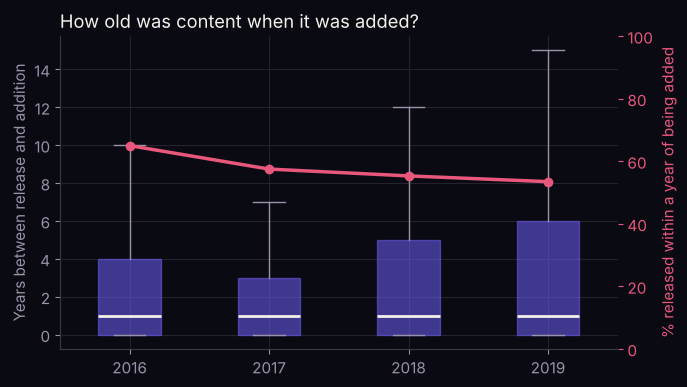

In [9]:
fig, ax = plt.subplots(figsize=(7,4))
data = [g['age_at_add'].clip(upper=40) for _, g in win.groupby('year_added')]
bp = ax.boxplot(data, tick_labels=age.index.astype(str), showfliers=False, patch_artist=True, medianprops=dict(color=IVORY, lw=2))
for b in bp['boxes']: b.set(facecolor=VIOLET, alpha=0.55, edgecolor=VIOLET)
for el in ['whiskers','caps']: [w.set_color(MUTED) for w in bp[el]]
ax2 = ax.twinx(); ax2.plot(range(1,5), age['fresh']*100, color=PINK, marker='o', lw=2.5); ax2.set_ylim(0,100)
ax2.set_ylabel('% released within a year of being added', color=PINK); ax2.tick_params(colors=PINK); ax2.grid(False)
ax.set_ylabel('Years between release and addition')
ax.set_title('How old was content when it was added?', loc='left', color=IVORY)
fig.tight_layout(); fig.savefig('figures/04_age_at_addition.png'); plt.show()

## 5. Summary table for the write-up

In [10]:
summary = pd.DataFrame({
  'TV share': tv['TV share'],
  'Non-US share': intl['Non-US share'],
  'Median age at addition (years)': age['median'],
  'Released within a year': age['fresh'],
  'Titles added': tv[['Movie','TV Show']].sum(axis=1)})
summary.round(3).to_csv('figures/summary.csv'); summary.round(3)

,TV share,Non-US share,Median age at addition (years),Released within a year,Titles added
year_added,,,,,
2016,0.421,0.518,1.0,0.650,456
2017,0.298,0.603,1.0,0.575,1299
2018,0.276,0.610,1.0,0.553,1782
2019,0.342,0.520,1.0,0.535,2347


## Summary dashboard

One image summarising the research question, headline numbers and key charts. It is rebuilt from the results above every time the notebook runs.

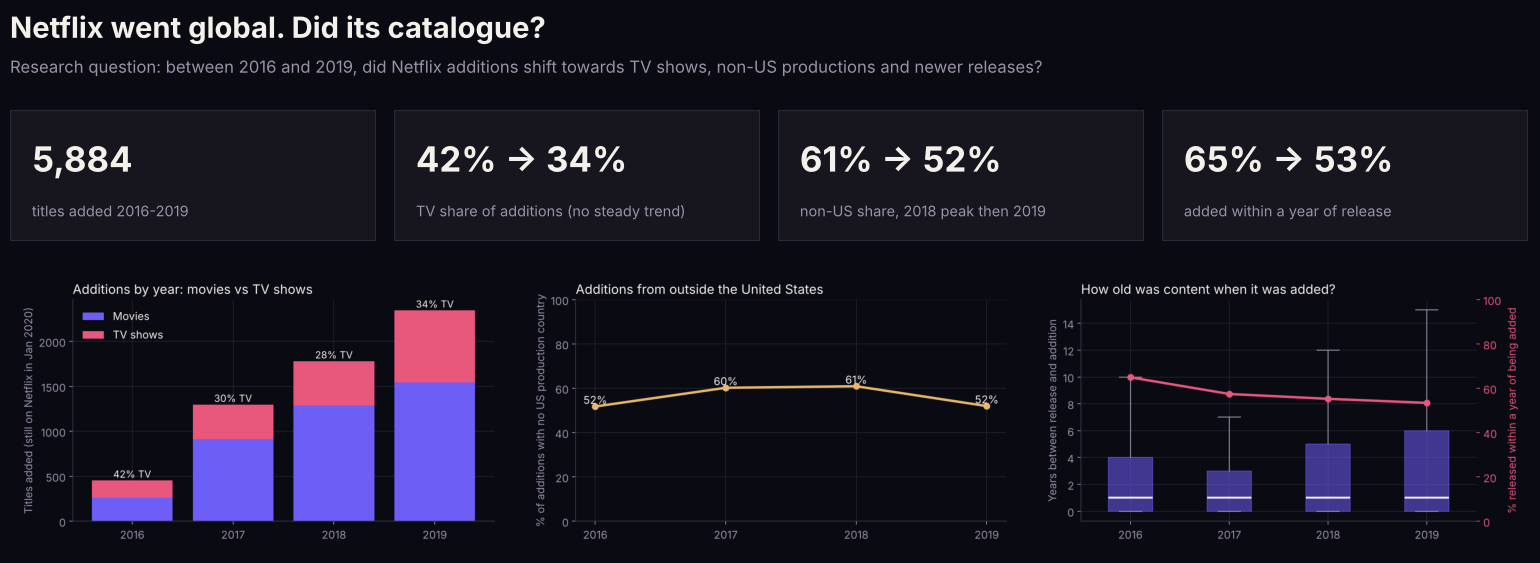

In [11]:
FG = IVORY
import matplotlib.image as mpimg
def dashboard(title, question, kpis, panels, out='figures/dashboard.png'):
    imgs = [mpimg.imread(p) for p in panels]
    W, m = 16, len(panels)
    pw = W*(0.96/m - 0.01)
    ph = max(pw*i.shape[0]/i.shape[1] for i in imgs)
    top = 2.7                                   # inches for title, question and KPI tiles
    H = top + ph + 0.25
    fig = plt.figure(figsize=(W, H))
    fig.text(0.02, 1-0.25/H, title, fontsize=21, color=FG, weight='bold', va='top')
    fig.text(0.02, 1-0.72/H, question, fontsize=12, color=MUTED, va='top')
    n = len(kpis)
    for i, (v, l) in enumerate(kpis):
        ax = fig.add_axes([0.02 + i*(0.96/n), 1-2.55/H, 0.96/n - 0.012, 1.3/H])
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_facecolor('#17161F')
        for s in ax.spines.values(): s.set_visible(True); s.set_color('#2B2938')
        ax.text(0.06, 0.62, v, fontsize=25, weight='bold', color=FG, transform=ax.transAxes, va='center')
        ax.text(0.06, 0.22, l, fontsize=10.5, color=MUTED, transform=ax.transAxes, va='center')
    for j, img in enumerate(imgs):
        ax = fig.add_axes([0.02 + j*(0.96/m), 0.1/H, 0.96/m - 0.01, ph/H])
        ax.imshow(img); ax.axis('off')
    fig.savefig(out, dpi=110); plt.show()

dashboard('Netflix went global. Did its catalogue?',
  'Research question: between 2016 and 2019, did Netflix additions shift towards TV shows, non-US productions and newer releases?',
  [(f"{int(tv[['Movie','TV Show']].to_numpy().sum()):,}", 'titles added 2016-2019'),
   (f"{tv.loc[2016,'TV share']:.0%} -> {tv.loc[2019,'TV share']:.0%}", 'TV share of additions (no steady trend)'),
   (f"{intl.loc[2018,'Non-US share']:.0%} -> {intl.loc[2019,'Non-US share']:.0%}", 'non-US share, 2018 peak then 2019'),
   (f"{age.loc[2016,'fresh']:.0%} -> {age.loc[2019,'fresh']:.0%}", 'added within a year of release')],
  ['figures/01_type_by_year.png','figures/02_international_share.png','figures/04_age_at_addition.png'])